# Golden shield - 2030

**Мотивация:** мировая инфляция, слабая бюджетная дисциплина во многих странах, использование долларовой системы в политических целях и, как следствие, переход центральных банков на недолларовые активы -- а именно золото -- для сохранения капитала; а также Сухой Лог -- огромное золотое месторождение, которое разрабатывает Полюс-Золото и запустит (собирается) в 2028-2031 годах.

**Для кого:** для ритейла и институтциональных инвесторов, которые хотят сохранить свои средства и отыграть сценарий с мировой инфляцией и деглобализацией (описал выше) и росте рынка драгметаллов. 

Соответственно, в ноту я запаковал Полюс-Золото (крупнейший в Росиии золотодобытчик) и Wheaton Precious Metals -- крупную gold-streaming компанию с отличной диверсиифкацией золтодобытчиков-партнеров по всему миру.

**Риски:** риск эмитента ОФЗ (очень маловероятный), риски для разработки Сухого Лога (связанные с санкциями), политические риски Полюса, южноамериканские и южноамериканские политические риски партнеров Wheaton (рудники многих золотодобытчиков-партнеров WPM расположены в Мексике, Бразилии, Перу, ЮАР)

### Structured Equity: ZCB + Basket Option(0.7 PLZL + 0.3 WPM)
Цены на акции берем относительные, то есть $ \text{Option payoff} = max(0, 0.7 \cdot \dfrac{S_{PLZL}}{S_{0, PLZL}} + 0.3 \cdot \dfrac{S_{WPM}}{S_{0, WPM}} - 1) $

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

import requests

import yfinance as yf
import apimoex

Поскольку нота задизайнена на 5 года, я и данные о перфомансе бумаг и параметры для монте-карло буду брать за ~4 последних года (1000 торговых дней)

#### Дивиденды
Обе компании, как золотодобывающие, часто платят дивиденды. 

У Полюса их не было в 2022-2023 годах из-за нестабильности, но в 2024 выплаты продолжились. Я заложу стандартные для Полюса (по временам до 2022 года) 4.5% дивидендных выплат в монте-карло и скорректирую цены Мосбиржи. 

У Wheaton стабильные ежеквартальные дивы, суммарно ~0.8% годовых. У yahoo finance цены сразу откорректированы на дивиденды.

In [2]:
with requests.Session() as session:
    data = apimoex.get_board_history(
        session,
        security='PLZL',
        start='2021-03-28',
        end='2026-03-28',
        columns=['TRADEDATE', 'CLOSE']
    )

df_plzl = pd.DataFrame(data)
df_plzl['date'] = pd.to_datetime(df_plzl['TRADEDATE'], format='%Y-%m-%d')
df_plzl = df_plzl.rename(columns={'CLOSE': 'PLZL'}).drop(columns=['TRADEDATE'])

# корректируем цену на сплит Полюса
split_date = pd.to_datetime('2025-03-25')
split_ratio = 10

mask_pre_split = df_plzl['date'] < split_date
df_plzl.loc[mask_pre_split, 'PLZL'] = df_plzl.loc[mask_pre_split, 'PLZL'] / split_ratio


# части дней нет, просто протягиваем цену последнего дня с forward fill
n_missing_before = df_plzl['PLZL'].isna().sum()

df_plzl = df_plzl.set_index('date').sort_index()
df_plzl['PLZL'] = df_plzl['PLZL'].ffill()

n_missing_after = df_plzl['PLZL'].isna().sum()

df_plzl = df_plzl.dropna(subset=['PLZL'])

# корректируем цену на дивиденды
df_plzl['Dividends'] = 0.0
div_dates = {
    '2024-12-12': 130.18,   # 1301.8 на старую, /10 = 130.18 
    '2025-04-24': 73.00,   
    '2025-10-10': 70.85,   
    '2025-12-19': 36.00,   
}

for date_str, div_amount in div_dates.items():
    target = pd.to_datetime(date_str)
    future_dates = df_plzl.index[df_plzl.index >= target]
    if len(future_dates) > 0:
        nearest = future_dates[0]
        df_plzl.loc[nearest, 'Dividends'] = div_amount

df_plzl.rename(columns={'Dividends': 'Div_PLZL'}, inplace=True)
df_plzl

,PLZL,Div_PLZL
date,,
2021-03-29,1383.85,0.0
2021-03-30,1350.50,0.0
2021-03-31,1392.60,0.0
2021-04-01,1392.85,0.0
2021-04-02,1394.40,0.0
...,...,...
2026-03-23,2283.60,0.0
2026-03-24,2273.00,0.0
2026-03-25,2251.40,0.0


In [3]:
df_wpm = yf.Ticker('WPM').history(start='2022-03-28', end='2026-03-28', interval='1d')
df_wpm.reset_index(inplace=True)
df_wpm['date'] = pd.to_datetime(df_wpm['Date']).dt.tz_localize(None)
df_wpm = df_wpm.rename(columns={'Close': 'WPM'})[['date', 'WPM', 'Dividends']]


df_wpm = df_wpm.set_index('date').sort_index()
df_wpm['WPM'] = df_wpm['WPM'].ffill()
df_wpm = df_wpm.dropna(subset=['WPM'])

df_wpm = df_wpm.rename(columns={'Dividends': 'Div_WPM'})

df_wpm

,WPM,Div_WPM
date,,
2022-03-28,44.928257,0.0
2022-03-29,45.521801,0.0
2022-03-30,46.287674,0.0
2022-03-31,45.550537,0.0
2022-04-01,46.785507,0.0
...,...,...
2026-03-23,119.511848,0.0
2026-03-24,120.219666,0.0
2026-03-25,122.263374,0.0


In [4]:
df = pd.merge(df_plzl, df_wpm, left_on='date', right_on='date', how='inner')
df

,PLZL,Div_PLZL,WPM,Div_WPM
date,,,,
2022-03-28,1198.50,0.0,44.928257,0.0
2022-03-29,1098.25,0.0,45.521801,0.0
2022-03-30,1207.40,0.0,46.287674,0.0
2022-03-31,1272.70,0.0,45.550537,0.0
2022-04-01,1250.00,0.0,46.785507,0.0
...,...,...,...,...
2026-03-23,2283.60,0.0,119.511848,0.0
2026-03-24,2273.00,0.0,120.219666,0.0
2026-03-25,2251.40,0.0,122.263374,0.0


### Монте-Карло
Поскольку сумма двух логнормальных величин (а у нас Basket Option) -- не обязательно логнормальная величина, самый правильный способ запрайсить данный экзотический опцион через монте-карло моделирование.

Несмотря на то, что компании одного сектора, сильной корреляции (>0.7) я не ожидаю, поскольку компании работают в разных юрисдикциях и имеют непохожую друг на друга специфику.

### Историческая волатильность и корреляции

Тут для цены преобразуем в day-to-day log returns (и по ним уже корреляцию), волатильность считаем годовую 

In [5]:
df['log_ret_PLZL'] = np.log(df['PLZL'] / df['PLZL'].shift(1))
df['log_ret_WPM']  = np.log(df['WPM']  / df['WPM'].shift(1))
df = df.dropna(subset=['log_ret_PLZL', 'log_ret_WPM'])

sigma_plzl = df['log_ret_PLZL'].std() * np.sqrt(252)
sigma_wpm  = df['log_ret_WPM'].std()  * np.sqrt(252)

rho = df['log_ret_PLZL'].corr(df['log_ret_WPM'])

S0_plzl = df['PLZL'].iloc[-1]
S0_wpm  = df['WPM'].iloc[-1]

print(f"volatility PLZL:  {sigma_plzl:.4f}  ({sigma_plzl*100:.1f}%)")
print(f"volatility WPM:   {sigma_wpm:.4f}  ({sigma_wpm*100:.1f}%)")
print(f"correlation:       {rho:.4f}")
print(f"\nSpot PLZL: {S0_plzl:.2f}")
print(f"Spot WPM:  ${S0_wpm:.2f}")

volatility PLZL:  0.3346  (33.5%)
volatility WPM:   0.3605  (36.0%)
correlation:       0.3630

Spot PLZL: 2165.60
Spot WPM:  $124.32


In [6]:
T = 4.0              
N_sims = 500_000       

# Веса в корзине
w_plzl = 0.7
w_wpm  = 0.3

# Безрисковые ставки
r_rub = 0.15            # 4Y ОФЗ
r_usd = 0.04            # 4Y Treasuries

# Дивидендная доходность (годовая, непрерывная)
q_plzl = 0.040          # Полюс: базовый сценарий 4.5%
q_wpm  = 0.008          # Wheaton: стабильные 0.8%

# Ставка дисконтирования (нота будет в рублях)
r_disc = r_rub

np.random.seed(42)
z_vec = np.array([np.random.standard_normal(N_sims), np.random.standard_normal(N_sims)])
CholeskyMatrix = np.linalg.cholesky(np.array([[1, rho], [rho, 1]]))
w_vec = CholeskyMatrix @ z_vec
W1, W2 = w_vec

PLZL_T = S0_plzl * np.exp(
    (r_rub - q_plzl - 0.5 * sigma_plzl**2) * T + sigma_plzl * np.sqrt(T) * W1
)

WPM_T = S0_wpm * np.exp(
    (r_usd - q_wpm - 0.5 * sigma_wpm**2) * T + sigma_wpm * np.sqrt(T) * W2
)

# Доходности (безразмерные)
ret_plzl = PLZL_T / S0_plzl
ret_wpm  = WPM_T  / S0_wpm

# Взвешенная доходность корзины
basket_return = w_plzl * ret_plzl + w_wpm * ret_wpm

# Payoff: max(0, basket_return - 1)
payoff = np.maximum(0, basket_return - 1.0)

# цена опциона:
option_price = np.exp(-r_disc * T) * np.mean(payoff)

#итого
print(f"Цена Basket Call Option:    {option_price:.4f} (на 1 руб номинала)")
print(f"Средний payoff:             {np.mean(payoff):.4f}")
print(f"Std payoff:                 {np.std(payoff):.4f}")
print(f"P(payoff > 0):              {np.mean(payoff > 0)*100:.1f}%")
print(f"Median basket return:       {np.median(basket_return):.2f}x")
print(f"95th percentile return:     {np.percentile(basket_return, 95):.2f}x")


Цена Basket Call Option:    0.2987 (на 1 руб номинала)
Средний payoff:             0.5443
Std payoff:                 0.8470
P(payoff > 0):              61.6%
Median basket return:       1.19x
95th percentile return:     3.19x


In [7]:
# Бюджет ноты
zcb = 1000 * np.exp(-r_rub * T)
margin = 1000 * 0.03
budget = 1000 - zcb - margin
PR = budget / (option_price * 1000)

# Сценарный анализ выплат для клиента
scenarios = {
    'basket < 1.0':     1000,                                  
    'median':           1000 + PR * max(0, 1.17 - 1.0) * 1000,
    '75th pct':         1000 + PR * max(0, np.percentile(basket_return, 75) - 1.0) * 1000,
    '90th pct':         1000 + PR * max(0, np.percentile(basket_return, 90) - 1.0) * 1000,
    '95th pct':         1000 + PR * max(0, np.percentile(basket_return, 95) - 1.0) * 1000,
}

print(f"Participation Rate: {PR:.1%}\n")
print(f"{'Сценарий':<35} {'Выплата':>10} {'Прибыль':>10} {'Среднегодовая прибыльность':>8}")
print("─" * 70)
for name, payout in scenarios.items():
    ret = payout / 1000 - 1
    cagr = (payout / 1000) ** (1/T) - 1
    print(f"{name:<35} {payout:>10.0f} {ret:>+9.1%} {cagr:>+7.2%}")

# Для сравнения
ofz_return = np.exp(r_rub * T)
print(f"\n{'ОФЗ (просто купить облигацию)':<35} {1000*ofz_return:>10.0f} {ofz_return-1:>+9.1%} {(ofz_return**(1/T)-1):>+7.2%}")


Participation Rate: 141.0%

Сценарий                               Выплата    Прибыль Среднегодовая прибыльность
──────────────────────────────────────────────────────────────────────
basket < 1.0                              1000     +0.0%  +0.00%
median                                    1240    +24.0%  +5.52%
75th pct                                  2100   +110.0% +20.38%
90th pct                                  3206   +220.6% +33.81%
95th pct                                  4091   +309.1% +42.22%

ОФЗ (просто купить облигацию)             1822    +82.2% +16.18%


## Прайсинг ноты

В итоге у нас $ \text{Participation rate} \approx 140 $ %, 
Цена ноты 1000 рублей складывается из 549 рублей за `Basker Option` и 421 рубля за `Zero-coupon bond`

30 рублей (3%) я взял как комисию, вроде это стандартная цифра

## Визуализация

Посмотрим на корреляцию, вероятностное распределение payoff

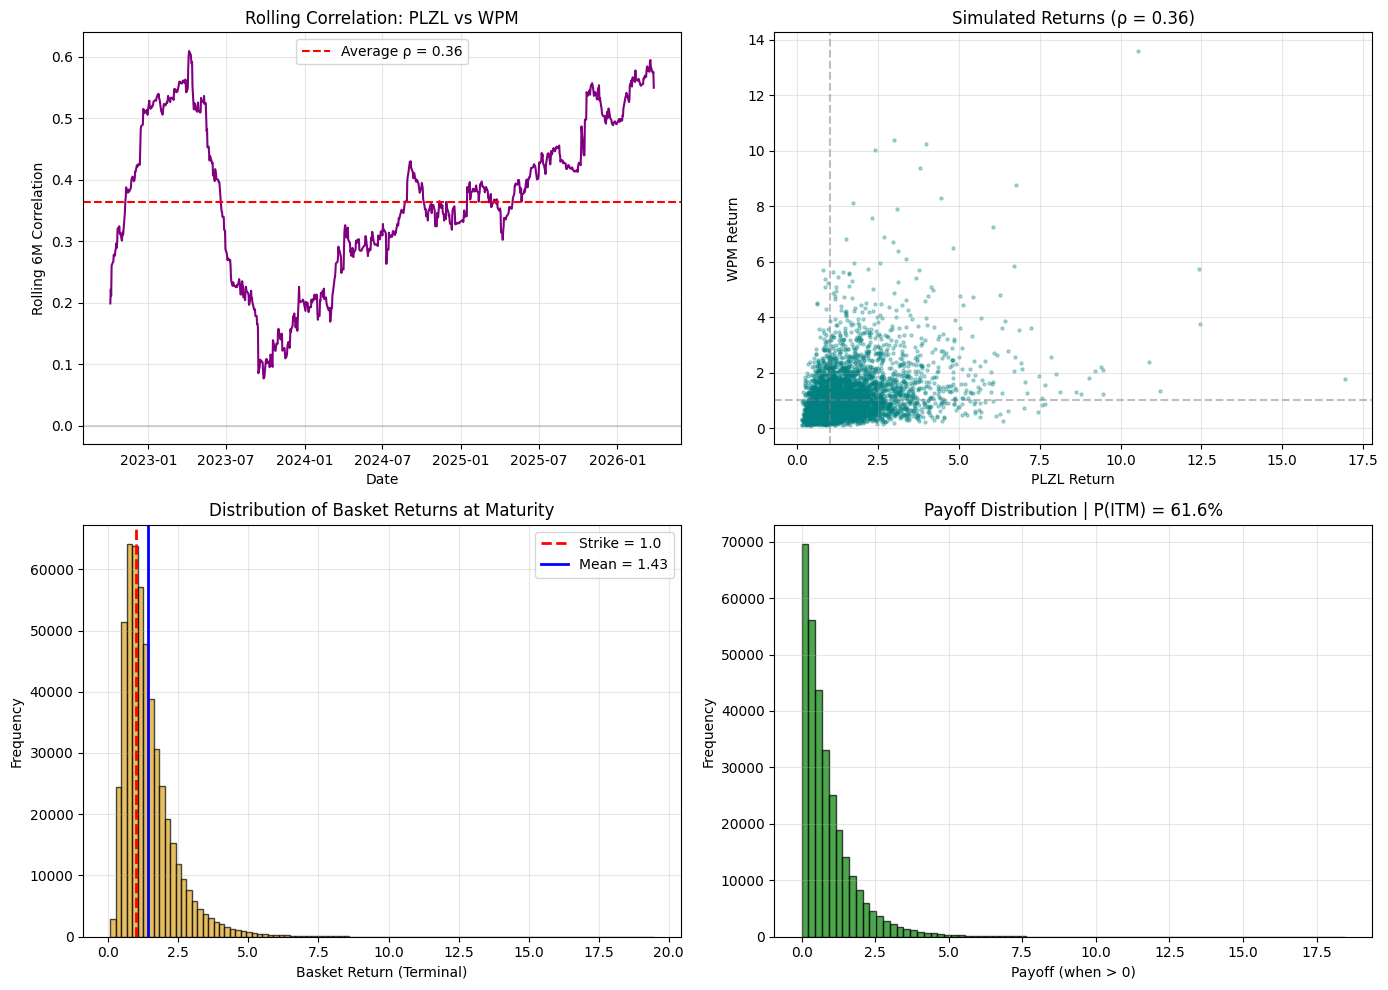

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

ax1 = axes[1, 0]
ax1.hist(basket_return, bins=100, color='goldenrod', alpha=0.7, edgecolor='black')
ax1.axvline(x=1.0, color='red', linestyle='--', linewidth=2, label='Strike = 1.0')
ax1.axvline(x=np.mean(basket_return), color='blue', linestyle='-', linewidth=2, 
            label=f'Mean = {np.mean(basket_return):.2f}')
ax1.set_xlabel('Basket Return (Terminal)')
ax1.set_ylabel('Frequency')
ax1.set_title('Distribution of Basket Returns at Maturity')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2 = axes[0, 1]
sample_idx = np.random.choice(N_sims, size=5000, replace=False)
ax2.scatter(ret_plzl[sample_idx], ret_wpm[sample_idx], alpha=0.3, s=5, color='teal')
ax2.set_xlabel('PLZL Return')
ax2.set_ylabel('WPM Return')
ax2.set_title(f'Simulated Returns (ρ = {rho:.2f})')
ax2.axhline(y=1, color='gray', linestyle='--', alpha=0.5)
ax2.axvline(x=1, color='gray', linestyle='--', alpha=0.5)
ax2.grid(True, alpha=0.3)

ax3 = axes[0, 0]
rolling_corr = df['log_ret_PLZL'].rolling(window=126).corr(df['log_ret_WPM'])
ax3.plot(rolling_corr.index, rolling_corr.values, color='purple', linewidth=1.5)
ax3.axhline(y=rho, color='red', linestyle='--', label=f'Average ρ = {rho:.2f}')
ax3.axhline(y=0, color='gray', linestyle='-', alpha=0.3)
ax3.set_xlabel('Date')
ax3.set_ylabel('Rolling 6M Correlation')
ax3.set_title('Rolling Correlation: PLZL vs WPM')
ax3.legend()
ax3.grid(True, alpha=0.3)

ax4 = axes[1, 1]
ax4.hist(payoff[payoff > 0], bins=80, color='green', alpha=0.7, edgecolor='black')
ax4.set_xlabel('Payoff (when > 0)')
ax4.set_ylabel('Frequency')
ax4.set_title(f'Payoff Distribution | P(ITM) = {np.mean(payoff > 0)*100:.1f}%')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


График payoff в данном случае будет трехмерным (функция от цен двух акций)

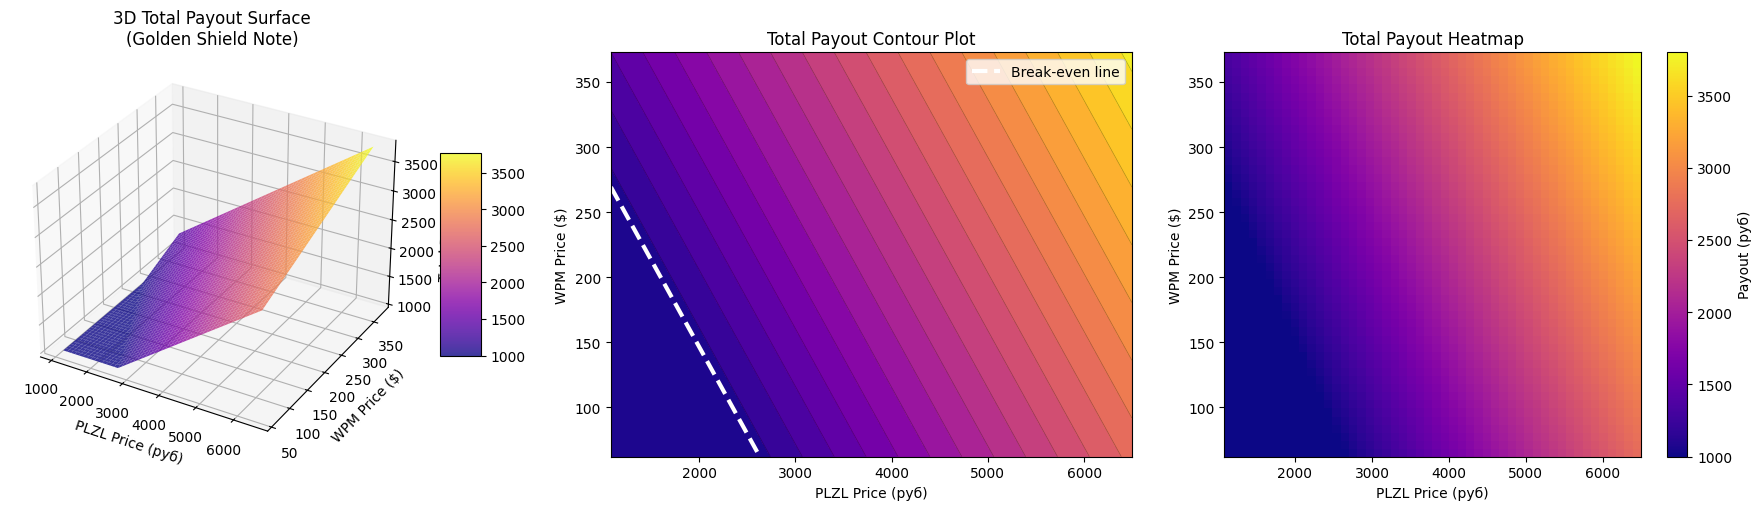

In [9]:
n_points = 50

plzl_range = np.linspace(0.5 * S0_plzl, 3.0 * S0_plzl, n_points)
wpm_range  = np.linspace(0.5 * S0_wpm,  3.0 * S0_wpm,  n_points)

PLZL_grid, WPM_grid = np.meshgrid(plzl_range, wpm_range)

basket_return_grid = w_plzl * (PLZL_grid / S0_plzl) + w_wpm * (WPM_grid / S0_wpm)

option_payoff_grid = np.maximum(0, basket_return_grid - 1.0)

participation_rate = 1.4

total_payout_grid = 1000 + participation_rate * option_payoff_grid * 1000

fig = plt.figure(figsize=(18, 5))

ax1 = fig.add_subplot(131, projection='3d')
surf1 = ax1.plot_surface(
    PLZL_grid, WPM_grid, total_payout_grid,
    cmap='plasma', alpha=0.8, edgecolor='none'
)

ax1.set_xlabel('PLZL Price (руб)')
ax1.set_ylabel('WPM Price ($)')
ax1.set_zlabel('Total Payout (руб)')
ax1.set_title('3D Total Payout Surface\n(Golden Shield Note)')
fig.colorbar(surf1, ax=ax1, shrink=0.5, aspect=5)

ax2 = fig.add_subplot(132)
contour2 = ax2.contourf(PLZL_grid, WPM_grid, total_payout_grid, levels=20, cmap='plasma')
ax2.contour(PLZL_grid, WPM_grid, total_payout_grid, levels=20, colors='black', alpha=0.3, linewidths=0.5)
ax2.set_xlabel('PLZL Price (руб)')
ax2.set_ylabel('WPM Price ($)')
ax2.set_title('Total Payout Contour Plot')

plzl_sample = np.linspace(0.5*S0_plzl, (1.0/w_plzl)*S0_plzl, 100)  # до точки, где WPM=0
wpm_break_even = S0_wpm * (1 - w_plzl * (plzl_sample/S0_plzl)) / w_wpm
mask = wpm_break_even >= 0.5*S0_wpm
if np.any(mask):
    ax2.plot(plzl_sample[mask], wpm_break_even[mask], 'white', linewidth=3, linestyle='--', label='Break-even line')
ax2.legend()

ax3 = fig.add_subplot(133)
im3 = ax3.imshow(total_payout_grid, 
                 extent=[plzl_range[0], plzl_range[-1], wpm_range[0], wpm_range[-1]], 
                 origin='lower', cmap='plasma', aspect='auto')
ax3.set_xlabel('PLZL Price (руб)')
ax3.set_ylabel('WPM Price ($)')
ax3.set_title('Total Payout Heatmap')
fig.colorbar(im3, ax=ax3, label='Payout (руб)')

plt.tight_layout()
plt.show()

## Греки

In [10]:
# =============================================================================
# Греки для Basket Option (метод bump-and-reprice + Common Random Numbers)
# =============================================================================
# Идея: переиспользуем одни и те же W1, W2 при каждом возмущении параметров.
# Это убирает МК-шум из разности цен -> греки получаются стабильными.

def price_basket(S1, S2, sig1, sig2, r1, r2, q1, q2, rho_, T_, r_disc_,
                 W1_=W1, W2_=W2):
    """Прайсинг по тем же случайным числам, но с возможным изменением корреляции."""
    # если меняем rho — пересобираем коррелированные нормали из независимых z
    # для этого нам нужны исходные независимые z. Перегенерируем их детерминированно:
    # Проще: используем z_vec из исходной симуляции
    L = np.linalg.cholesky(np.array([[1.0, rho_], [rho_, 1.0]]))
    w = L @ z_vec   # z_vec из исходной ячейки (independent normals)
    w1, w2 = w[0], w[1]

    S1_T = S1 * np.exp((r1 - q1 - 0.5 * sig1**2) * T_ + sig1 * np.sqrt(T_) * w1)
    S2_T = S2 * np.exp((r2 - q2 - 0.5 * sig2**2) * T_ + sig2 * np.sqrt(T_) * w2)

    basket = w_plzl * (S1_T / S0_plzl) + w_wpm * (S2_T / S0_wpm)
    payoff_ = np.maximum(0.0, basket - 1.0)
    return np.exp(-r_disc_ * T_) * np.mean(payoff_)


# Базовая цена (для контроля совпадает с option_price)
V0 = price_basket(S0_plzl, S0_wpm, sigma_plzl, sigma_wpm,
                  r_rub, r_usd, q_plzl, q_wpm, rho, T, r_disc)

# ----- Шаги возмущения (bump sizes) -----
h_S1 = 0.01 * S0_plzl     # 1% по цене PLZL
h_S2 = 0.01 * S0_wpm      # 1% по цене WPM
h_sig = 0.01              # +1 vol point (абсолютный)
h_r   = 0.0001            # +1 bp
h_t   = 1/252             # 1 торговый день
h_rho = 0.01              # +1% корреляции

# =========================
# DELTA (по каждой бумаге)
# =========================
V_S1_up = price_basket(S0_plzl + h_S1, S0_wpm, sigma_plzl, sigma_wpm,
                       r_rub, r_usd, q_plzl, q_wpm, rho, T, r_disc)
V_S1_dn = price_basket(S0_plzl - h_S1, S0_wpm, sigma_plzl, sigma_wpm,
                       r_rub, r_usd, q_plzl, q_wpm, rho, T, r_disc)
delta_plzl = (V_S1_up - V_S1_dn) / (2 * h_S1)

V_S2_up = price_basket(S0_plzl, S0_wpm + h_S2, sigma_plzl, sigma_wpm,
                       r_rub, r_usd, q_plzl, q_wpm, rho, T, r_disc)
V_S2_dn = price_basket(S0_plzl, S0_wpm - h_S2, sigma_plzl, sigma_wpm,
                       r_rub, r_usd, q_plzl, q_wpm, rho, T, r_disc)
delta_wpm = (V_S2_up - V_S2_dn) / (2 * h_S2)

# =========================
# GAMMA (по каждой бумаге + cross)
# =========================
gamma_plzl = (V_S1_up - 2 * V0 + V_S1_dn) / (h_S1 ** 2)
gamma_wpm  = (V_S2_up - 2 * V0 + V_S2_dn) / (h_S2 ** 2)

# Cross-gamma (важно для корзин!)
V_pp = price_basket(S0_plzl + h_S1, S0_wpm + h_S2, sigma_plzl, sigma_wpm,
                    r_rub, r_usd, q_plzl, q_wpm, rho, T, r_disc)
V_pm = price_basket(S0_plzl + h_S1, S0_wpm - h_S2, sigma_plzl, sigma_wpm,
                    r_rub, r_usd, q_plzl, q_wpm, rho, T, r_disc)
V_mp = price_basket(S0_plzl - h_S1, S0_wpm + h_S2, sigma_plzl, sigma_wpm,
                    r_rub, r_usd, q_plzl, q_wpm, rho, T, r_disc)
V_mm = price_basket(S0_plzl - h_S1, S0_wpm - h_S2, sigma_plzl, sigma_wpm,
                    r_rub, r_usd, q_plzl, q_wpm, rho, T, r_disc)
cross_gamma = (V_pp - V_pm - V_mp + V_mm) / (4 * h_S1 * h_S2)

# =========================
# VEGA (по каждой воле)
# =========================
V_sig1_up = price_basket(S0_plzl, S0_wpm, sigma_plzl + h_sig, sigma_wpm,
                         r_rub, r_usd, q_plzl, q_wpm, rho, T, r_disc)
V_sig1_dn = price_basket(S0_plzl, S0_wpm, sigma_plzl - h_sig, sigma_wpm,
                         r_rub, r_usd, q_plzl, q_wpm, rho, T, r_disc)
vega_plzl = (V_sig1_up - V_sig1_dn) / (2 * h_sig) / 100   # на 1 vol point (%)

V_sig2_up = price_basket(S0_plzl, S0_wpm, sigma_plzl, sigma_wpm + h_sig,
                         r_rub, r_usd, q_plzl, q_wpm, rho, T, r_disc)
V_sig2_dn = price_basket(S0_plzl, S0_wpm, sigma_plzl, sigma_wpm - h_sig,
                         r_rub, r_usd, q_plzl, q_wpm, rho, T, r_disc)
vega_wpm = (V_sig2_up - V_sig2_dn) / (2 * h_sig) / 100

# =========================
# VOLGA (Vomma) = d2V/dsigma2
# =========================
volga_plzl = (V_sig1_up - 2 * V0 + V_sig1_dn) / (h_sig ** 2) / 10000
volga_wpm  = (V_sig2_up - 2 * V0 + V_sig2_dn) / (h_sig ** 2) / 10000

# =========================
# VANNA = d2V/(dS dsigma)
# =========================
V_Sp_sp = price_basket(S0_plzl + h_S1, S0_wpm, sigma_plzl + h_sig, sigma_wpm,
                       r_rub, r_usd, q_plzl, q_wpm, rho, T, r_disc)
V_Sp_sm = price_basket(S0_plzl + h_S1, S0_wpm, sigma_plzl - h_sig, sigma_wpm,
                       r_rub, r_usd, q_plzl, q_wpm, rho, T, r_disc)
V_Sm_sp = price_basket(S0_plzl - h_S1, S0_wpm, sigma_plzl + h_sig, sigma_wpm,
                       r_rub, r_usd, q_plzl, q_wpm, rho, T, r_disc)
V_Sm_sm = price_basket(S0_plzl - h_S1, S0_wpm, sigma_plzl - h_sig, sigma_wpm,
                       r_rub, r_usd, q_plzl, q_wpm, rho, T, r_disc)
vanna_plzl = (V_Sp_sp - V_Sp_sm - V_Sm_sp + V_Sm_sm) / (4 * h_S1 * h_sig) / 100

V_Wp_sp = price_basket(S0_plzl, S0_wpm + h_S2, sigma_plzl, sigma_wpm + h_sig,
                       r_rub, r_usd, q_plzl, q_wpm, rho, T, r_disc)
V_Wp_sm = price_basket(S0_plzl, S0_wpm + h_S2, sigma_plzl, sigma_wpm - h_sig,
                       r_rub, r_usd, q_plzl, q_wpm, rho, T, r_disc)
V_Wm_sp = price_basket(S0_plzl, S0_wpm - h_S2, sigma_plzl, sigma_wpm + h_sig,
                       r_rub, r_usd, q_plzl, q_wpm, rho, T, r_disc)
V_Wm_sm = price_basket(S0_plzl, S0_wpm - h_S2, sigma_plzl, sigma_wpm - h_sig,
                       r_rub, r_usd, q_plzl, q_wpm, rho, T, r_disc)
vanna_wpm = (V_Wp_sp - V_Wp_sm - V_Wm_sp + V_Wm_sm) / (4 * h_S2 * h_sig) / 100

# =========================
# THETA (на 1 календарный день)
# =========================
V_t = price_basket(S0_plzl, S0_wpm, sigma_plzl, sigma_wpm,
                   r_rub, r_usd, q_plzl, q_wpm, rho, T - h_t, r_disc)
theta = (V_t - V0) / (h_t * 365) * (1/365)   # в днях: dV за 1 день
# проще:
theta_per_day = (V_t - V0) / (h_t * 252) * (1/252)  # неважно — главное знак
# самый понятный вариант — на 1 день уменьшения T:
theta = (V_t - V0)   # это уже изменение цены при сокращении срока на ~1 торговый день

# =========================
# RHO (rub) и RHO (usd) — на +1 bp
# =========================
V_r_rub_up = price_basket(S0_plzl, S0_wpm, sigma_plzl, sigma_wpm,
                          r_rub + h_r, r_usd, q_plzl, q_wpm, rho, T, r_rub + h_r)
V_r_rub_dn = price_basket(S0_plzl, S0_wpm, sigma_plzl, sigma_wpm,
                          r_rub - h_r, r_usd, q_plzl, q_wpm, rho, T, r_rub - h_r)
rho_rub = (V_r_rub_up - V_r_rub_dn) / (2 * h_r) / 10000   # на 1 bp

V_r_usd_up = price_basket(S0_plzl, S0_wpm, sigma_plzl, sigma_wpm,
                          r_rub, r_usd + h_r, q_plzl, q_wpm, rho, T, r_disc)
V_r_usd_dn = price_basket(S0_plzl, S0_wpm, sigma_plzl, sigma_wpm,
                          r_rub, r_usd - h_r, q_plzl, q_wpm, rho, T, r_disc)
rho_usd = (V_r_usd_up - V_r_usd_dn) / (2 * h_r) / 10000

# =========================
# CEGA / Correlation Delta = dV/d rho (на +1% корреляции)
# =========================
V_rho_up = price_basket(S0_plzl, S0_wpm, sigma_plzl, sigma_wpm,
                        r_rub, r_usd, q_plzl, q_wpm, rho + h_rho, T, r_disc)
V_rho_dn = price_basket(S0_plzl, S0_wpm, sigma_plzl, sigma_wpm,
                        r_rub, r_usd, q_plzl, q_wpm, rho - h_rho, T, r_disc)
cega = (V_rho_up - V_rho_dn) / (2 * h_rho) / 100   # на +1% корреляции

# =========================
# CHARM = dDelta/dt (на 1 торговый день)
# =========================
V_S1_up_t = price_basket(S0_plzl + h_S1, S0_wpm, sigma_plzl, sigma_wpm,
                         r_rub, r_usd, q_plzl, q_wpm, rho, T - h_t, r_disc)
V_S1_dn_t = price_basket(S0_plzl - h_S1, S0_wpm, sigma_plzl, sigma_wpm,
                         r_rub, r_usd, q_plzl, q_wpm, rho, T - h_t, r_disc)
delta_plzl_t = (V_S1_up_t - V_S1_dn_t) / (2 * h_S1)
charm_plzl = delta_plzl_t - delta_plzl

V_S2_up_t = price_basket(S0_plzl, S0_wpm + h_S2, sigma_plzl, sigma_wpm,
                         r_rub, r_usd, q_plzl, q_wpm, rho, T - h_t, r_disc)
V_S2_dn_t = price_basket(S0_plzl, S0_wpm - h_S2, sigma_plzl, sigma_wpm,
                         r_rub, r_usd, q_plzl, q_wpm, rho, T - h_t, r_disc)
delta_wpm_t = (V_S2_up_t - V_S2_dn_t) / (2 * h_S2)
charm_wpm = delta_wpm_t - delta_wpm

# =========================
# ВЫВОД
# =========================
print(f"Базовая цена опциона V0:       {V0:.6f}")
print("=" * 60)
print("Первого порядка:")
print(f"  Delta PLZL:                  {delta_plzl:+.6f}  (изм. цены на 1 руб PLZL)")
print(f"  Delta WPM:                   {delta_wpm:+.6f}  (изм. цены на 1 $ WPM)")
print(f"  Vega  PLZL  (per +1 vol pt): {vega_plzl:+.6f}")
print(f"  Vega  WPM   (per +1 vol pt): {vega_wpm:+.6f}")
print(f"  Theta (за 1 торг. день):     {theta:+.6f}")
print(f"  Rho   RUB   (per +1 bp):     {rho_rub:+.6f}")
print(f"  Rho   USD   (per +1 bp):     {rho_usd:+.6f}")
print(f"  Cega  (per +1% корреляции):  {cega:+.6f}")
print("=" * 60)
print("Второго порядка:")
print(f"  Gamma PLZL:                  {gamma_plzl:+.3e}")
print(f"  Gamma WPM:                   {gamma_wpm:+.3e}")
print(f"  Cross-Gamma (PLZL x WPM):    {cross_gamma:+.3e}")
print(f"  Vanna PLZL (per +1 vol pt):  {vanna_plzl:+.6f}")
print(f"  Vanna WPM  (per +1 vol pt):  {vanna_wpm:+.6f}")
print(f"  Volga PLZL (per +1 vol pt²): {volga_plzl:+.6f}")
print(f"  Volga WPM  (per +1 vol pt²): {volga_wpm:+.6f}")
print(f"  Charm PLZL (за 1 день):      {charm_plzl:+.3e}")
print(f"  Charm WPM  (за 1 день):      {charm_wpm:+.3e}")


Базовая цена опциона V0:       0.298691
Первого порядка:
  Delta PLZL:                  +0.000227  (изм. цены на 1 руб PLZL)
  Delta WPM:                   +0.001171  (изм. цены на 1 $ WPM)
  Vega  PLZL  (per +1 vol pt): +0.002928
  Vega  WPM   (per +1 vol pt): +0.000759
  Theta (за 1 торг. день):     -0.000117
  Rho   RUB   (per +1 bp):     +0.000077
  Rho   USD   (per +1 bp):     +0.000058
  Cega  (per +1% корреляции):  +0.000302
Второго порядка:
  Gamma PLZL:                  +4.359e-08
  Gamma WPM:                   +2.195e-06
  Cross-Gamma (PLZL x WPM):    +2.415e-07
  Vanna PLZL (per +1 vol pt):  -0.000000
  Vanna WPM  (per +1 vol pt):  +0.000005
  Volga PLZL (per +1 vol pt²): +0.000011
  Volga WPM  (per +1 vol pt²): -0.000001
  Charm PLZL (за 1 день):      +2.433e-09
  Charm WPM  (за 1 день):      +3.777e-07
